<a href="https://colab.research.google.com/github/192524103simats-star/CSA4705/blob/main/UNIT_4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

import tensorflow as tf
from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, Dense

(x_train,y_train),(x_test,y_test)=imdb.load_data(num_words=5000)
x_train=pad_sequences(x_train,maxlen=100)
x_test=pad_sequences(x_test,maxlen=100)

model=Sequential([
    Embedding(5000,32),
    SimpleRNN(32),
    Dense(1,activation='sigmoid')
])
model.compile(optimizer='adam',loss='binary_crossentropy',metrics=['accuracy'])
model.fit(x_train,y_train,epochs=3,batch_size=64,validation_split=0.2)
print("Test Accuracy:",model.evaluate(x_test,y_test)[1])


17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/3
313/313 ━━━━━━━━━━━━━━━━━━━━ 12s 32ms/step - accuracy: 0.6631 - loss: 0.5861 - val_accuracy: 0.7726 - val_loss: 0.4746
Epoch 2/3
313/313 ━━━━━━━━━━━━━━━━━━━━ 10s 32ms/step - accuracy: 0.8470 - loss: 0.3580 - val_accuracy: 0.8284 - val_loss: 0.4001
Epoch 3/3
313/313 ━━━━━━━━━━━━━━━━━━━━ 10s 31ms/step - accuracy: 0.9033 - loss: 0.2449 - val_accuracy: 0.8228 - val_loss: 0.4260
782/782 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.8304 - loss: 0.4155
Test Accuracy: 0.8303599953651428


In [3]:

import tensorflow as tf
import numpy as np

text="deep learning is an interesting technology. "
chars=sorted(set(text))
c2i={c:i for i,c in enumerate(chars)}
data=np.array([c2i[c] for c in text])

X=np.array([data[i:i+5] for i in range(len(data)-5)])
y=data[5:]

model=tf.keras.Sequential([
    tf.keras.layers.Embedding(len(chars),16),
    tf.keras.layers.SimpleRNN(32),
    tf.keras.layers.Dense(len(chars),activation='softmax')
])
model.compile(optimizer='adam',loss='sparse_categorical_crossentropy')
model.fit(X,y,epochs=100,verbose=0)

seed="deep "
seq=[c2i[c] for c in seed]
for i in range(30):
    p=model.predict(np.array([seq[-5:]]),verbose=0)[0]
    seq.append(np.random.choice(len(chars),p=p))
print("Generated Text:",''.join(chars[i] for i in seq))


Generated Text: deep llarnintenesoeyg gytscantsngst


In [4]:

import numpy as np
import tensorflow as tf
from sklearn.preprocessing import MinMaxScaler

np.random.seed(42)
data=np.cumsum(np.random.randn(500))+100

scaler=MinMaxScaler()
data=scaler.fit_transform(data.reshape(-1,1))

X=np.array([data[i:i+10] for i in range(490)])
y=data[10:]

model=tf.keras.Sequential([
    tf.keras.layers.SimpleRNN(32,input_shape=(10,1)),
    tf.keras.layers.Dense(1)
])
model.compile(optimizer='adam',loss='mse')
model.fit(X,y,epochs=10,verbose=0)

pred=model.predict(X[-5:])
print("Predicted Stock Prices:")
print(scaler.inverse_transform(pred).flatten())


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 146ms/step
Predicted Stock Prices:
[105.30788 106.17804 106.31771 105.92319 105.78954]


In [5]:

import numpy as np
import tensorflow as tf

data=np.sin(np.arange(500)*0.1)+np.random.normal(0,0.1,500)+5

X=np.array([data[i:i+10] for i in range(490)])
y=np.array([data[i+10] for i in range(490)])

X=X.reshape(-1,10,1)

model=tf.keras.Sequential([
    tf.keras.layers.SimpleRNN(32,input_shape=(10,1)),
    tf.keras.layers.Dense(1)
])
model.compile(optimizer='adam',loss='mse')
model.fit(X,y,epochs=10,verbose=0)

print("Predicted Consumption:")
print(model.predict(X[-5:]).flatten())


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Predicted Consumption:
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 143ms/step
[4.5220575 4.538287  4.592746  4.714177  4.7454176]


In [6]:

import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

text=["deep learning is powerful",
      "deep learning is useful",
      "machine learning is interesting",
      "machine learning is powerful"]

tok=Tokenizer()
tok.fit_on_texts(text)
seq=tok.texts_to_sequences(text)

X=[]; y=[]
for s in seq:
    for i in range(1,len(s)):
        X.append(s[:i])
        y.append(s[i])

X=pad_sequences(X)
y=tf.keras.utils.to_categorical(y,num_classes=len(tok.word_index)+1)

model=tf.keras.Sequential([
    tf.keras.layers.Embedding(len(tok.word_index)+1,16),
    tf.keras.layers.SimpleRNN(32),
    tf.keras.layers.Dense(len(tok.word_index)+1,activation='softmax')
])
model.compile(optimizer='adam',loss='categorical_crossentropy')
model.fit(X,y,epochs=100,verbose=0)

p=model.predict(pad_sequences([tok.texts_to_sequences(["deep learning"])[0]],maxlen=X.shape[1]),verbose=0)
print("Next Word:",tok.index_word[p.argmax()])


Next Word: is


In [7]:

import numpy as np
import tensorflow as tf
from sklearn.metrics import mean_squared_error

data=np.sin(np.arange(300)*0.1)+5
X=np.array([data[i:i+10] for i in range(290)]).reshape(-1,10,1)
y=data[10:]

for layer in [tf.keras.layers.SimpleRNN(32),
              tf.keras.layers.LSTM(32)]:
    model=tf.keras.Sequential([
        tf.keras.layers.Input(shape=(10,1)),
        layer,
        tf.keras.layers.Dense(1)
    ])
    model.compile(optimizer='adam',loss='mse')
    model.fit(X[:230],y[:230],epochs=10,verbose=0)
    pred=model.predict(X[230:],verbose=0)
    print(type(layer).__name__,
          "MSE:",mean_squared_error(y[230:],pred))


SimpleRNN MSE: 0.4966145848283725
LSTM MSE: 0.45506987276286054


In [8]:

import numpy as np
import tensorflow as tf
from sklearn.metrics import mean_squared_error, mean_absolute_error

data=np.cumsum(np.random.randn(500))+100
X=np.array([data[i:i+10] for i in range(490)])
y=data[10:]
X=X.reshape(-1,10,1)

model=tf.keras.Sequential([
    tf.keras.layers.LSTM(32,input_shape=(10,1)),
    tf.keras.layers.Dense(1)
])
model.compile(optimizer='adam',loss='mse')
model.fit(X[:400],y[:400],epochs=10,verbose=0)

p=model.predict(X[400:],verbose=0)
print("MAE:",mean_absolute_error(y[400:],p))
print("MSE:",mean_squared_error(y[400:],p))


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


MAE: 133.96954610475197
MSE: 17978.78037905586


In [9]:

import numpy as np
import tensorflow as tf

data=np.random.rand(500,3)

X=np.array([data[i:i+10] for i in range(490)])
y=data[10:]

model=tf.keras.Sequential([
    tf.keras.layers.GRU(32,input_shape=(10,3)),
    tf.keras.layers.Dense(3)
])
model.compile(optimizer='adam',loss='mse')
model.fit(X,y,epochs=10,verbose=0)

print("Predicted Weather:")
print(model.predict(X[-5:],verbose=0))


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Predicted Weather:
[[0.4225145  0.4045275  0.47443014]
 [0.45344412 0.4711864  0.43648398]
 [0.4717288  0.48490533 0.48981005]
 [0.5091176  0.52253705 0.5119526 ]
 [0.54124135 0.5541566  0.5331375 ]]


In [10]:

import numpy as np
import tensorflow as tf
from sklearn.metrics import mean_squared_error

data=np.sin(np.arange(300)*0.1)
X=np.array([data[i:i+10] for i in range(290)]).reshape(-1,10,1)
y=data[10:]

for layer in [tf.keras.layers.SimpleRNN(32),
              tf.keras.layers.LSTM(32),
              tf.keras.layers.GRU(32)]:
    model=tf.keras.Sequential([
        tf.keras.layers.Input(shape=(10,1)),
        layer,
        tf.keras.layers.Dense(1)
    ])
    model.compile(optimizer='adam',loss='mse')
    model.fit(X[:230],y[:230],epochs=10,verbose=0)
    p=model.predict(X[230:],verbose=0)
    print(type(layer).__name__,
          "MSE:",mean_squared_error(y[230:],p))


SimpleRNN MSE: 0.0031648837847982583
LSTM MSE: 0.09357658290915179
GRU MSE: 0.03830371906780184


In [11]:

import numpy as np
import tensorflow as tf

data=np.random.rand(500,3)

X=np.array([data[i:i+10] for i in range(490)])
y=data[10:]

model=tf.keras.Sequential([
    tf.keras.layers.SimpleRNN(32,return_sequences=True,input_shape=(10,3)),
    tf.keras.layers.SimpleRNN(16),
    tf.keras.layers.Dense(3)
])
model.compile(optimizer='adam',loss='mse')
model.fit(X,y,epochs=10,verbose=0)

print("Machine Prediction:")
print(model.predict(X[-5:]))


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Machine Prediction:
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 233ms/step
[[0.4179076  0.5037956  0.34791487]
 [0.398685   0.43430114 0.35326234]
 [0.57075924 0.6440471  0.59327793]
 [0.50999457 0.6221762  0.6038701 ]
 [0.5185501  0.54445577 0.35884038]]


Gradient Values:
[0.5, 0.25, 0.125, 0.0625, 0.03125, 0.015625, 0.0078125, 0.00390625, 0.001953125, 0.0009765625, 0.00048828125, 0.000244140625, 0.0001220703125, 6.103515625e-05, 3.0517578125e-05, 1.52587890625e-05, 7.62939453125e-06, 3.814697265625e-06, 1.9073486328125e-06, 9.5367431640625e-07, 4.76837158203125e-07, 2.384185791015625e-07, 1.1920928955078125e-07, 5.960464477539063e-08, 2.9802322387695312e-08, 1.4901161193847656e-08, 7.450580596923828e-09, 3.725290298461914e-09, 1.862645149230957e-09, 9.313225746154785e-10]


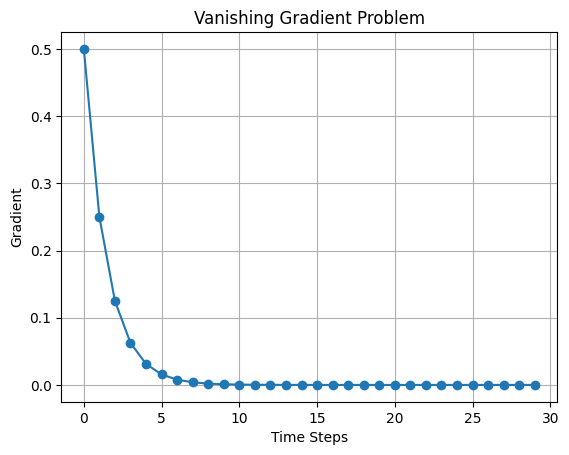

In [12]:

import numpy as np
import matplotlib.pyplot as plt

gradient=1.0
values=[]

for i in range(30):
    gradient=gradient*0.5
    values.append(gradient)

print("Gradient Values:")
print(values)

plt.plot(values,marker='o')
plt.xlabel("Time Steps")
plt.ylabel("Gradient")
plt.title("Vanishing Gradient Problem")
plt.grid()
plt.show()


In [13]:

import numpy as np
import tensorflow as tf

data=np.sin(np.arange(300)*0.1)

for n in [5,10,20,30]:
    X=np.array([data[i:i+n] for i in range(300-n)])
    y=data[n:]
    X=X.reshape(-1,n,1)

    model=tf.keras.Sequential([
        tf.keras.layers.SimpleRNN(16,input_shape=(n,1)),
        tf.keras.layers.Dense(1)
    ])
    model.compile(optimizer='adam',loss='mse')
    model.fit(X[:200],y[:200],epochs=5,verbose=0)

    loss=model.evaluate(X[200:],y[200:],verbose=0)
    print("Sequence Length:",n,"Loss:",loss)


Sequence Length: 5 Loss: 0.07465412467718124
Sequence Length: 10 Loss: 0.0002957164542749524
Sequence Length: 20 Loss: 0.05998336151242256
Sequence Length: 30 Loss: 0.14068832993507385


In [14]:

import numpy as np
import tensorflow as tf

data=np.sin(np.arange(200)*0.1)
X=np.array([data[i:i+10] for i in range(190)]).reshape(-1,10,1)
y=data[10:]

for lr in [0.001,0.01]:
    for units in [16,32]:
        model=tf.keras.Sequential([
            tf.keras.layers.Input(shape=(10,1)),
            tf.keras.layers.LSTM(units),
            tf.keras.layers.Dense(1)
        ])
        model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=lr),loss='mse')
        h=model.fit(X,y,epochs=5,batch_size=16,verbose=0)
        print("LR:",lr,"Units:",units,
              "Loss:",h.history['loss'][-1])


LR: 0.001 Units: 16 Loss: 0.17908945679664612
LR: 0.001 Units: 32 Loss: 0.1147398129105568
LR: 0.01 Units: 16 Loss: 0.0029550204053521156
LR: 0.01 Units: 32 Loss: 0.0007520552608184516


In [15]:

import numpy as np
import tensorflow as tf
from sklearn.metrics import mean_absolute_error,mean_squared_error

data=np.sin(np.arange(300)*0.1)+5
X=np.array([data[i:i+10] for i in range(290)]).reshape(-1,10,1)
y=data[10:]

model=tf.keras.Sequential([
    tf.keras.layers.SimpleRNN(32,input_shape=(10,1)),
    tf.keras.layers.Dense(1)
])
model.compile(optimizer='adam',loss='mse')
model.fit(X[:230],y[:230],epochs=10,verbose=0)

p=model.predict(X[230:],verbose=0)
mae=mean_absolute_error(y[230:],p)
mse=mean_squared_error(y[230:],p)
rmse=np.sqrt(mse)

print("MAE:",mae)
print("MSE:",mse)
print("RMSE:",rmse)


MAE: 0.6730159967795816
MSE: 0.5709292984538926
RMSE: 0.7555986358205609


In [16]:

import numpy as np
import tensorflow as tf
from sklearn.metrics import classification_report

X=np.random.randint(1,50,(200,10))
y=np.random.randint(0,3,200)

model=tf.keras.Sequential([
    tf.keras.layers.Embedding(50,16),
    tf.keras.layers.SimpleRNN(32),
    tf.keras.layers.Dense(3,activation='softmax')
])

model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

model.fit(X[:160],y[:160],epochs=5,verbose=0)

p=model.predict(X[160:],verbose=0).argmax(axis=1)

print(classification_report(y[160:],p,zero_division=0))


              precision    recall  f1-score   support

           0       0.17      0.08      0.11        13
           1       0.00      0.00      0.00        11
           2       0.31      0.56      0.40        16

    accuracy                           0.25        40
   macro avg       0.16      0.21      0.17        40
weighted avg       0.18      0.25      0.19        40



In [17]:

import tensorflow as tf
import numpy as np

# Sample sentence data
X=np.array([
    [1,2,3,4],[2,3,4,5],
    [6,7,8,9],[7,8,9,10]
])
y=np.array([1,1,0,0])

# Recursive composition model
inp=tf.keras.Input(shape=(4,))
x=tf.keras.layers.Embedding(11,16)(inp)

left=tf.keras.layers.Lambda(lambda a:a[:,0:2,:])(x)
right=tf.keras.layers.Lambda(lambda a:a[:,2:4,:])(x)

a=tf.keras.layers.Lambda(lambda a:tf.concat(
    [a[:,0,:],a[:,1,:]],axis=1))(left)
b=tf.keras.layers.Lambda(lambda a:tf.concat(
    [a[:,0,:],a[:,1,:]],axis=1))(right)

c=tf.keras.layers.Concatenate()([a,b])
c=tf.keras.layers.Dense(16,activation='tanh')(c)
out=tf.keras.layers.Dense(1,activation='sigmoid')(c)

model=tf.keras.Model(inp,out)
model.compile(optimizer='adam',
              loss='binary_crossentropy',
              metrics=['accuracy'])

model.fit(X,y,epochs=50,verbose=0)

print("Predictions:")
print((model.predict(X,verbose=0)>0.5).astype(int))


Predictions:
[[1]
 [1]
 [0]
 [0]]
